<center><h1>Zuo_Xiyi_HW2</h1></center>
<br>
<center><font size="4">Combined Cycle Power Plant</font></center>

**Name:** Xiyi Zuo
**GitHub Username:** Kiera111
**USC ID:** 9330953458


### Package imports

All dependencies are imported together so the notebook can be run sequentially from a clean kernel.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
ALPHA = 0.05
PREDICTORS = ["T", "V", "AP", "RH"]


## 1. Combined Cycle Power Plant Data Set


### (a) Download Data

The Combined Cycle Power Plant data were downloaded from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Combined+Cycle+Power+Plant). The file has five sheets that are shuffled copies of the same records. This notebook uses **Sheet 1** only, read with a path relative to the notebook.


In [2]:
data_path = Path("../data/CCPP/Folds5x2_pp.xlsx")
ccpp = pd.read_excel(data_path, sheet_name=0)
ccpp = ccpp.rename(columns={"AT": "T", "PE": "EP"})
ccpp.head()


,T,V,AP,RH,EP
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


The file stores temperature as `AT` and net energy output as `PE`. They are renamed to `T` and `EP` so the column names match the homework statement. `V`, `AP`, and `RH` are already named as in the assignment.


### (b) Exploring the data


#### i. rows and columns


In [3]:
n_rows, n_cols = ccpp.shape
print(f"Rows: {n_rows}")
print(f"Columns: {n_cols}")
print("Column names:", list(ccpp.columns))


Rows: 9568
Columns: 5
Column names: ['T', 'V', 'AP', 'RH', 'EP']


There are 9,568 rows and 5 columns. Each row is one hour of full-load operation. `T`, `V`, `AP`, and `RH` are the predictors (temperature, exhaust vacuum, ambient pressure, and relative humidity). `EP` is the response, the net hourly electrical energy output.


#### ii. pairwise scatterplots of all the variables


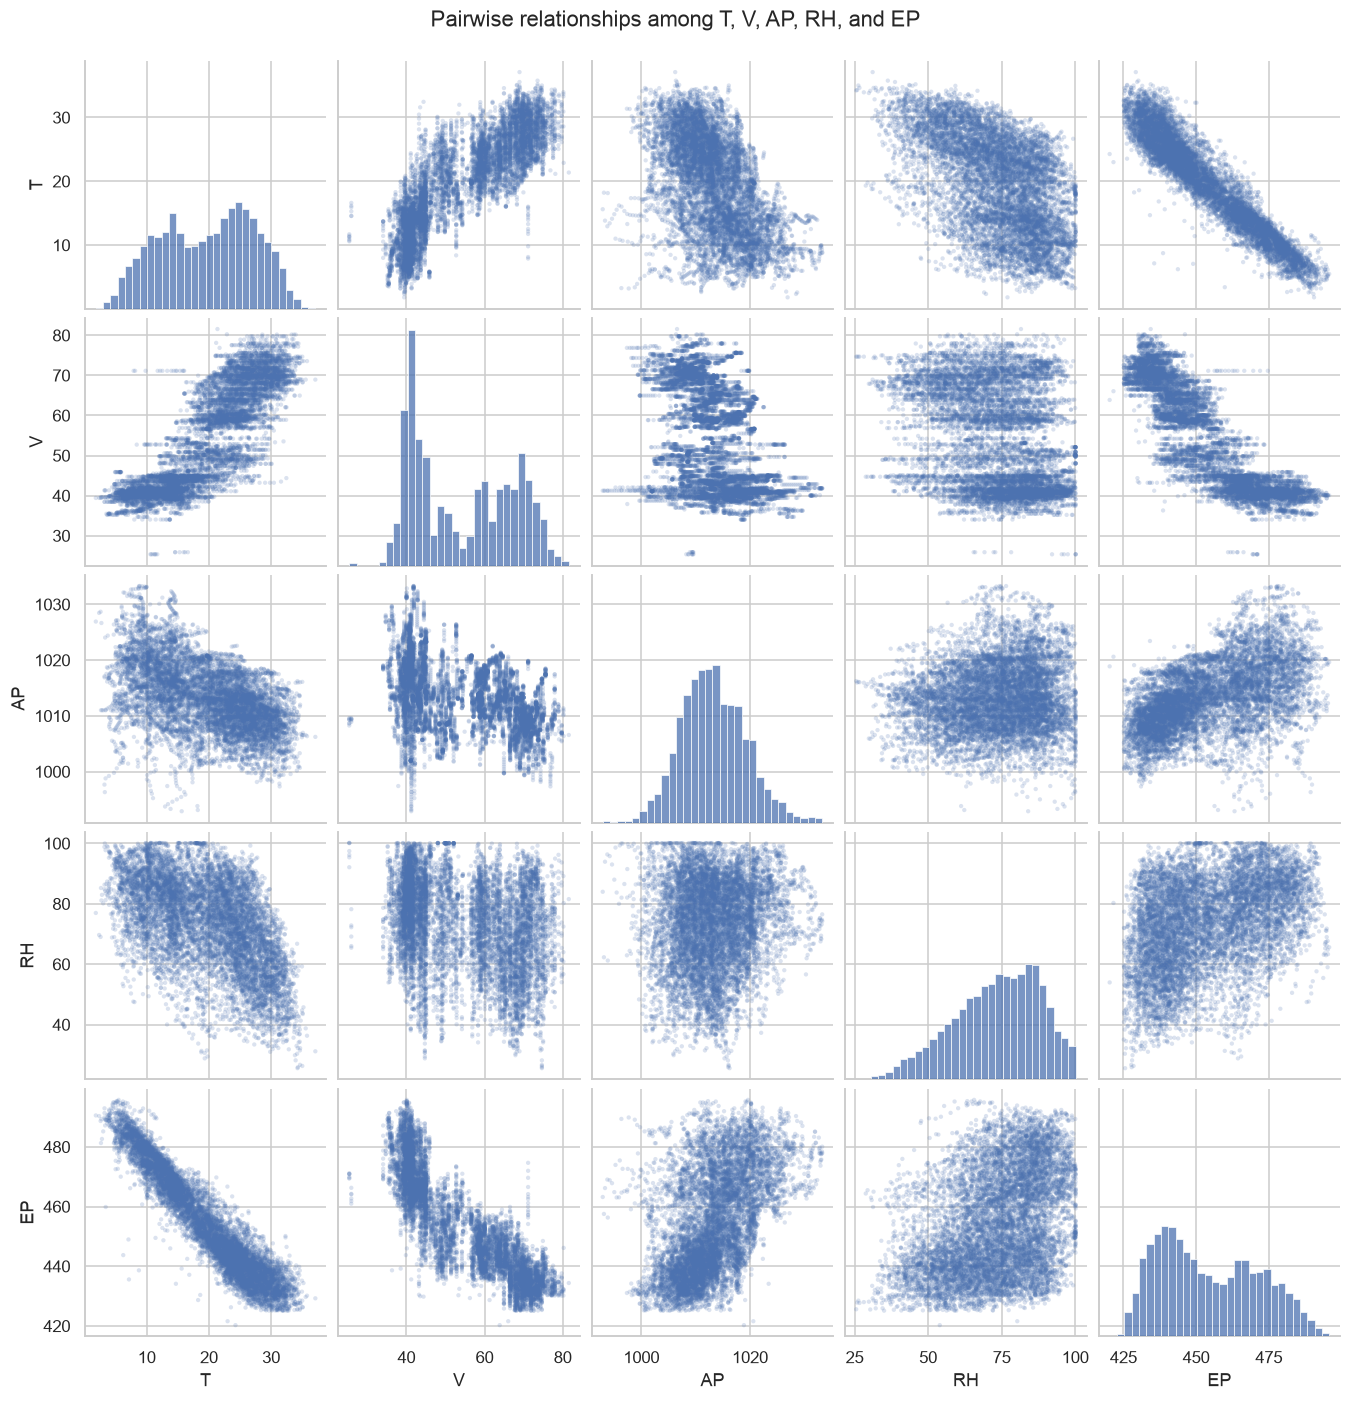

,T,V,AP,RH,EP
T,1.0000,0.8441,-0.5075,-0.5425,-0.9481
V,0.8441,1.0000,-0.4135,-0.3122,-0.8698
AP,-0.5075,-0.4135,1.0000,0.0996,0.5184
RH,-0.5425,-0.3122,0.0996,1.0000,0.3898
EP,-0.9481,-0.8698,0.5184,0.3898,1.0000


In [4]:
pairplot = sns.pairplot(
    ccpp,
    corner=False,
    diag_kind="hist",
    plot_kws={"s": 8, "alpha": 0.2, "edgecolor": "none"},
    diag_kws={"bins": 30},
)
pairplot.figure.suptitle("Pairwise relationships among T, V, AP, RH, and EP", y=1.02)
plt.show()

correlation = ccpp.corr()
display(correlation)


`T` and `EP` have a strong negative association (correlation about -0.95), and `V` and `EP` are also strongly negative (about -0.87). `AP` and `EP` are moderately positive (about 0.52), and `RH` and `EP` are more weakly positive (about 0.39). The predictors are not independent of each other: `T` and `V` move together (correlation about 0.84), and `T` is negatively associated with both `AP` and `RH`. The scatterplots are close to linear for `T` and `V`, with some curvature that later polynomial fits pick up.


#### iii. mean, the median, range, first and third quartiles, and interquartile ranges


In [5]:
summary = ccpp.describe().T
summary["range"] = summary["max"] - summary["min"]
summary["iqr"] = summary["75%"] - summary["25%"]
summary = summary.rename(
    columns={"50%": "median", "25%": "first_quartile", "75%": "third_quartile"}
)
summary = summary[["mean", "median", "range", "first_quartile", "third_quartile", "iqr"]]
summary


,mean,median,range,first_quartile,third_quartile,iqr
T,19.6512,20.345,35.30,13.5100,25.72,12.2100
V,54.3058,52.080,56.20,41.7400,66.54,24.8000
AP,1013.2591,1012.940,40.41,1009.1000,1017.26,8.1600
RH,73.3090,74.975,74.60,63.3275,84.83,21.5025
EP,454.3650,451.550,75.50,439.7500,468.43,28.6800


The table above is the requested summary. `EP` is centered near 454, with an interquartile range of about 28.7. `AP` varies over a narrow range (about 40) relative to its level near 1013, which matters later when powers of `AP` are formed.


### (c) Simple Linear Regression


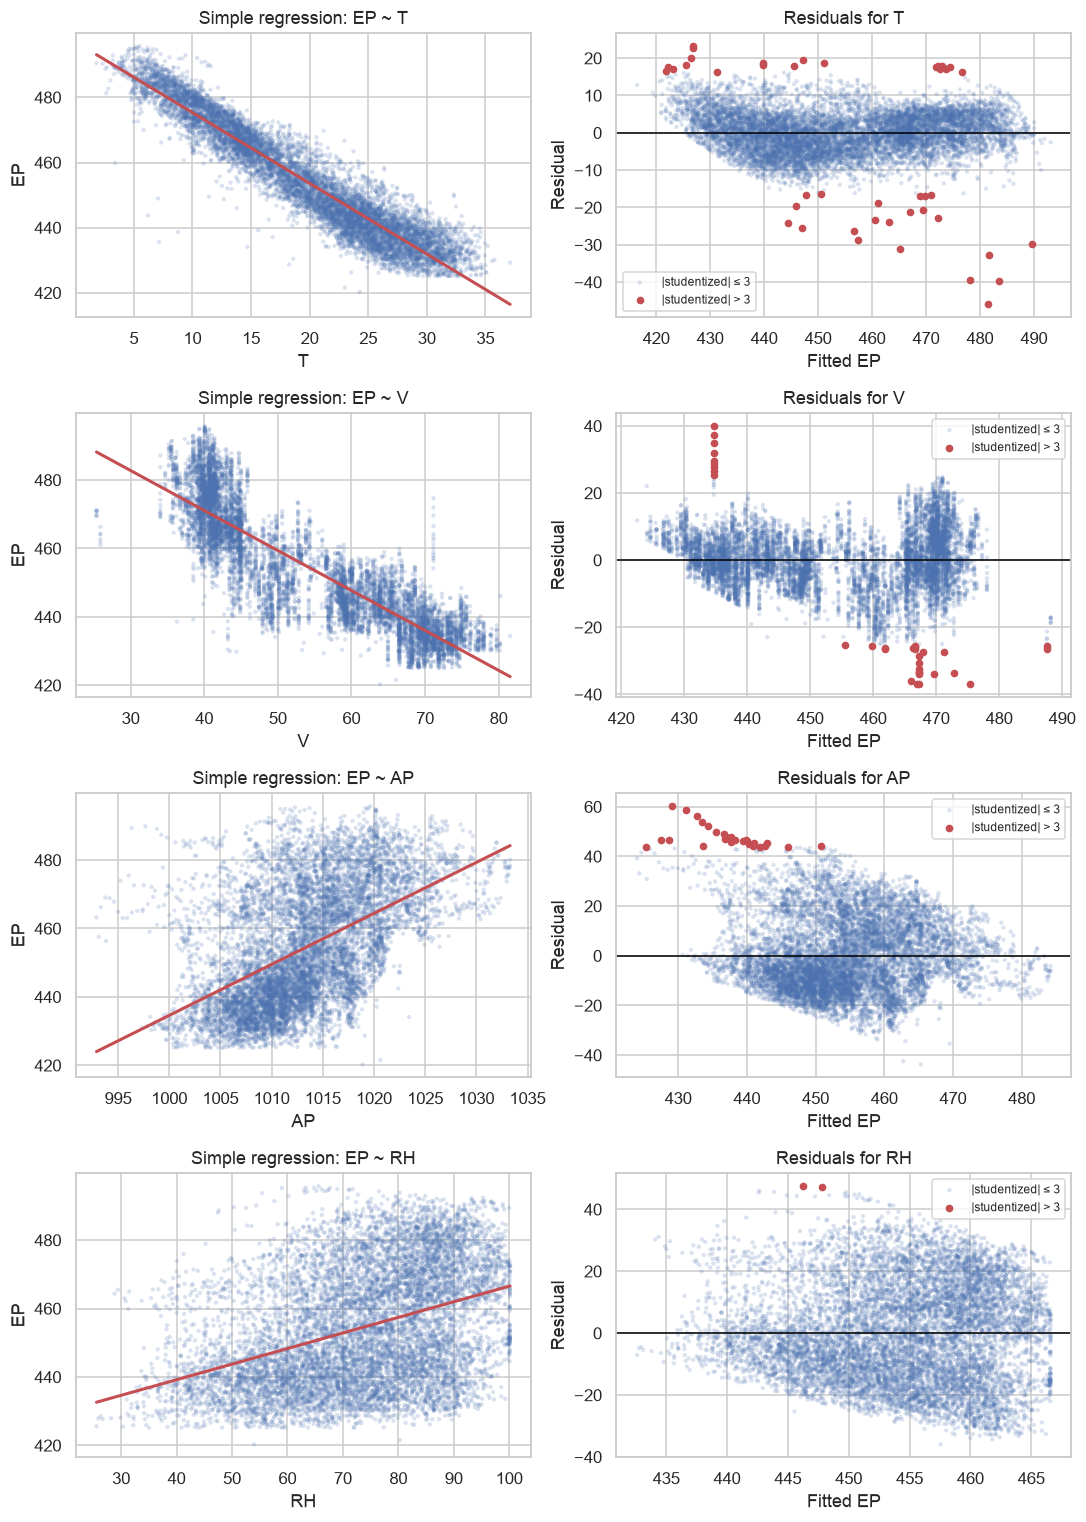

,intercept,slope,p_value,r_squared,n_outliers
predictor,,,,,
T,497.0341,-2.1713,0.0,0.8989,42
V,517.8015,-1.1681,0.0,0.7565,33
AP,-1055.2610,1.4899,0.0,0.2688,29
RH,420.9618,0.4557,0.0,0.1519,2


In [6]:
simple_models = {}
simple_rows = []

fig, axes = plt.subplots(len(PREDICTORS), 2, figsize=(10, 14))
for row, predictor in enumerate(PREDICTORS):
    result = smf.ols(f"EP ~ {predictor}", data=ccpp).fit()
    simple_models[predictor] = result
    studentized = result.get_influence().resid_studentized_internal
    outlier = np.abs(studentized) > 3
    simple_rows.append(
        {
            "predictor": predictor,
            "intercept": result.params["Intercept"],
            "slope": result.params[predictor],
            "p_value": result.pvalues[predictor],
            "r_squared": result.rsquared,
            "n_outliers": int(outlier.sum()),
        }
    )

    fitted = result.fittedvalues.to_numpy()
    observed_x = ccpp[predictor].to_numpy()
    order = np.argsort(observed_x)
    axes[row, 0].scatter(observed_x, ccpp["EP"], s=8, alpha=0.2, edgecolor="none")
    axes[row, 0].plot(observed_x[order], fitted[order], color="C3", linewidth=2)
    axes[row, 0].set_xlabel(predictor)
    axes[row, 0].set_ylabel("EP")
    axes[row, 0].set_title(f"Simple regression: EP ~ {predictor}")

    residual = result.resid.to_numpy()
    axes[row, 1].scatter(
        fitted[~outlier], residual[~outlier], s=8, alpha=0.2, edgecolor="none", label="|studentized| ≤ 3"
    )
    axes[row, 1].scatter(
        fitted[outlier], residual[outlier], s=16, color="C3", label="|studentized| > 3"
    )
    axes[row, 1].axhline(0, color="black", linewidth=1)
    axes[row, 1].set_xlabel("Fitted EP")
    axes[row, 1].set_ylabel("Residual")
    axes[row, 1].set_title(f"Residuals for {predictor}")
    axes[row, 1].legend(loc="best", fontsize=8)

fig.tight_layout()
plt.show()

simple_table = pd.DataFrame(simple_rows).set_index("predictor")
display(simple_table)


Each predictor, fit by itself, has a slope p-value far below 0.05, so each simple regression shows a statistically significant association with `EP`.

- `T` and `V` have negative slopes and explain most of the variation (`R^2` about 0.90 and 0.76).
- `AP` and `RH` have positive slopes but much smaller `R^2` (about 0.27 and 0.15).

Points with absolute internal studentized residual greater than 3 are marked on the residual plots. There are 42, 33, 29, and 2 such points for `T`, `V`, `AP`, and `RH`. With 9,568 observations, that is a small fraction, and the plots do not show a separate cluster that looks like a recording error. I leave these points in the data. Removing them would not change the sign or the significance of any simple slope.


### (d) Multiple Regression


In [7]:
multiple = smf.ols("EP ~ T + V + AP + RH", data=ccpp).fit()
print(multiple.summary())

multiple_slopes = pd.DataFrame(
    {
        "coefficient": multiple.params,
        "p_value": multiple.pvalues,
    }
)
multiple_slopes


                            OLS Regression Results                            
Dep. Variable:                     EP   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:35:40   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

,coefficient,p_value
Intercept,454.6093,0.0000e+00
T,-1.9775,0.0000e+00
V,-0.2339,4.3753e-215
AP,0.0621,5.5071e-11
RH,-0.1581,3.1046e-293


The multiple regression of `EP` on all four predictors has `R^2` about 0.929. Every slope has a p-value far below 0.05, so for every predictor we reject `H0: beta_j = 0` at alpha = 0.05. `T` and `V` stay negative. `AP` stays positive but is much smaller than in the simple regression. `RH` changes sign: its multiple-regression coefficient is negative.


### (e) 1c Compare to 1d


,simple_slope,multiple_slope
T,-2.1713,-1.9775
V,-1.1681,-0.2339
AP,1.4899,0.0621
RH,0.4557,-0.1581


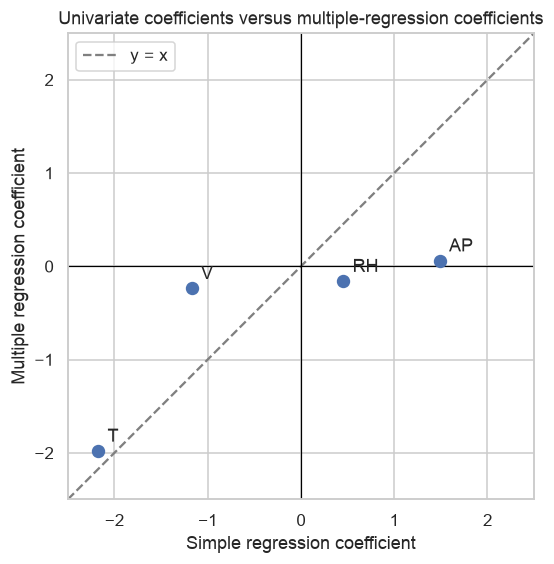

In [8]:
comparison = pd.DataFrame(
    {
        "simple_slope": simple_table["slope"],
        "multiple_slope": multiple.params[PREDICTORS],
    }
)
display(comparison)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(comparison["simple_slope"], comparison["multiple_slope"], s=60, zorder=3)
for predictor, row in comparison.iterrows():
    ax.annotate(
        predictor,
        (row["simple_slope"], row["multiple_slope"]),
        textcoords="offset points",
        xytext=(6, 6),
    )
limit = np.max(np.abs(comparison.to_numpy())) * 1.15
ax.plot([-limit, limit], [-limit, limit], linestyle="--", color="gray", label="y = x")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_xlabel("Simple regression coefficient")
ax.set_ylabel("Multiple regression coefficient")
ax.set_title("Univariate coefficients versus multiple-regression coefficients")
ax.legend()
ax.set_aspect("equal", adjustable="box")
plt.show()


The four points do not fall on the line `y = x`, so controlling for the other predictors changes the coefficients. `T` moves only slightly (about -2.17 to -1.98). `V` shrinks sharply (about -1.17 to -0.23) because `V` is strongly correlated with `T`; in the simple regression, `V` was partly standing in for temperature. `AP` also shrinks (about 1.49 to 0.06). `RH` is the clearest disagreement: the simple slope is positive (about 0.46) and the multiple-regression slope is negative (about -0.16). That happens because `RH` is negatively correlated with `T`, and the simple `RH` slope was picking up the effect of cooler hours.


### (f) Nonlinear Association


For each predictor `X`, the model is `EP = beta0 + beta1 X + beta2 X^2 + beta3 X^3 + epsilon`. `AP` is near 1000, so the raw columns `AP`, `AP^2`, and `AP^3` are nearly collinear and the uncentered design is numerically singular. Each predictor is therefore centered before its powers are built. Centering does not change the cubic coefficient, and it makes the test of the quadratic term stable. A quadratic or cubic term with p-value below 0.05 is treated as evidence of a nonlinear association.


In [9]:
nonlinear_rows = []
for predictor in PREDICTORS:
    centered = ccpp.copy()
    centered["Xc"] = centered[predictor] - centered[predictor].mean()
    result = smf.ols("EP ~ Xc + I(Xc ** 2) + I(Xc ** 3)", data=centered).fit()
    nonlinear_rows.append(
        {
            "predictor": predictor,
            "p_linear": result.pvalues["Xc"],
            "p_quadratic": result.pvalues["I(Xc ** 2)"],
            "p_cubic": result.pvalues["I(Xc ** 3)"],
            "quadratic_significant": result.pvalues["I(Xc ** 2)"] < ALPHA,
            "cubic_significant": result.pvalues["I(Xc ** 3)"] < ALPHA,
            "condition_number": result.condition_number,
        }
    )

nonlinear_table = pd.DataFrame(nonlinear_rows).set_index("predictor")
nonlinear_table


,p_linear,p_quadratic,p_cubic,quadratic_significant,cubic_significant,condition_number
predictor,,,,,,
T,0.0000e+00,3.3118e-231,3.6522e-110,True,True,1332.2389
V,0.0000e+00,8.9770e-131,1.3735e-02,True,True,6312.0889
AP,0.0000e+00,2.1927e-46,2.1233e-67,True,True,1039.7752
RH,9.6487e-152,1.0139e-01,1.4403e-05,False,True,13502.8875


There is evidence of a nonlinear association for every predictor.

- `T` and `AP`: both the quadratic and cubic terms are significant.
- `V`: both terms are significant. The cubic p-value is about 0.014.
- `RH`: the cubic term is significant (p-value about 1.4e-5). The quadratic term is not (p-value about 0.10).


### (g) Interactions of Predictors


In [10]:
interaction_formula = (
    "EP ~ T + V + AP + RH + T:V + T:AP + T:RH + V:AP + V:RH + AP:RH"
)
interaction = smf.ols(interaction_formula, data=ccpp).fit()
interaction_table = pd.DataFrame(
    {
        "coefficient": interaction.params,
        "p_value": interaction.pvalues,
    }
)
interaction_table["significant"] = interaction_table["p_value"] < ALPHA
display(interaction_table)

pairwise = [name for name in interaction.params.index if ":" in name]
print("Significant pairwise interactions:")
print(interaction_table.loc[pairwise].query("significant").index.tolist())


,coefficient,p_value,significant
Intercept,685.7825,3.2316e-18,True
T,-4.3470,6.7019e-02,False
V,-7.6749,1.3713e-08,True
AP,-0.1524,4.7357e-02,True
RH,1.5709,4.2252e-02,True
T:V,0.0210,3.3334e-117,True
T:AP,0.0018,4.5205e-01,False
T:RH,-0.0052,1.2169e-10,True
V:AP,0.0068,2.8770e-07,True
V:RH,0.0008,8.6194e-02,False


Significant pairwise interactions:
['T:V', 'T:RH', 'V:AP', 'AP:RH']


The model contains the four main effects and the six pairwise products only. It does not include three-way or four-way products. At alpha = 0.05, these interaction terms are statistically significant: `T:V`, `T:RH`, `V:AP`, and `AP:RH`. `T:AP` (p-value about 0.45) and `V:RH` (p-value about 0.086) are not.


### (h) Improvement


In [11]:
train, test = train_test_split(ccpp, test_size=0.3, random_state=RANDOM_STATE)

baseline = smf.ols("EP ~ T + V + AP + RH", data=train).fit()
baseline_train_mse = mean_squared_error(train["EP"], baseline.predict(train))
baseline_test_mse = mean_squared_error(test["EP"], baseline.predict(test))

MAIN_EFFECTS = PREDICTORS
remaining = [
    "T",
    "V",
    "AP",
    "RH",
    "T:V",
    "T:AP",
    "T:RH",
    "V:AP",
    "V:RH",
    "AP:RH",
    "I(T ** 2)",
    "I(V ** 2)",
    "I(AP ** 2)",
    "I(RH ** 2)",
]


def protected_main_effects(terms):
    protected = set()
    for term in terms:
        if term in MAIN_EFFECTS:
            continue
        if term.startswith("I("):
            protected.add(term[2:].split()[0])
        elif ":" in term:
            protected.update(term.split(":"))
    return protected


removal_log = []
while True:
    fitted = smf.ols("EP ~ " + " + ".join(remaining), data=train).fit()
    pvalues = fitted.pvalues.drop("Intercept").sort_values(ascending=False)
    protected = protected_main_effects(remaining)
    removed_term = None
    for term, p_value in pvalues.items():
        if p_value <= ALPHA:
            break
        if term in MAIN_EFFECTS and term in protected:
            continue
        removed_term = term
        break
    if removed_term is None:
        break
    removal_log.append({"removed": removed_term, "p_value": pvalues[removed_term]})
    remaining.remove(removed_term)

improved = smf.ols("EP ~ " + " + ".join(remaining), data=train).fit()
improved_train_mse = mean_squared_error(train["EP"], improved.predict(train))
improved_test_mse = mean_squared_error(test["EP"], improved.predict(test))

print("Removed, most insignificant first:")
display(pd.DataFrame(removal_log))
print("Terms kept:", remaining)
mse_table = pd.DataFrame(
    {
        "train_mse": [baseline_train_mse, improved_train_mse],
        "test_mse": [baseline_test_mse, improved_test_mse],
    },
    index=["all_predictors", "interactions_and_quadratics"],
)
mse_table


Removed, most insignificant first:


,removed,p_value
0,T:AP,0.4923
1,V:RH,0.3791
2,I(V ** 2),0.0931


Terms kept: ['T', 'V', 'AP', 'RH', 'T:V', 'T:RH', 'V:AP', 'AP:RH', 'I(T ** 2)', 'I(AP ** 2)', 'I(RH ** 2)']


,train_mse,test_mse
all_predictors,20.3547,21.7414
interactions_and_quadratics,17.7087,19.0829


Both models are trained on the same 70% split (`random_state=552`) and scored on the remaining 30%.

The baseline model uses only `T`, `V`, `AP`, and `RH`. Its training MSE is about 20.35 and its test MSE is about 21.74.

The second model starts with those main effects, all six pairwise interactions, and a square of each predictor. Backward elimination drops the term with the largest p-value above 0.05, then refits. A main effect is kept while a still-included interaction or square uses that predictor. The dropped terms, in order, are `T:AP`, `V:RH`, and `I(V ** 2)`. The reduced model has training MSE about 17.71 and test MSE about 19.08. Adding the supported nonlinear and interaction terms lowers both errors, and the test error falls with the training error, so the gain is not only overfitting.


### (i) KNN


,best_k,train_mse,test_mse
raw,5,10.1173,17.2225
normalized,6,10.0778,16.0017


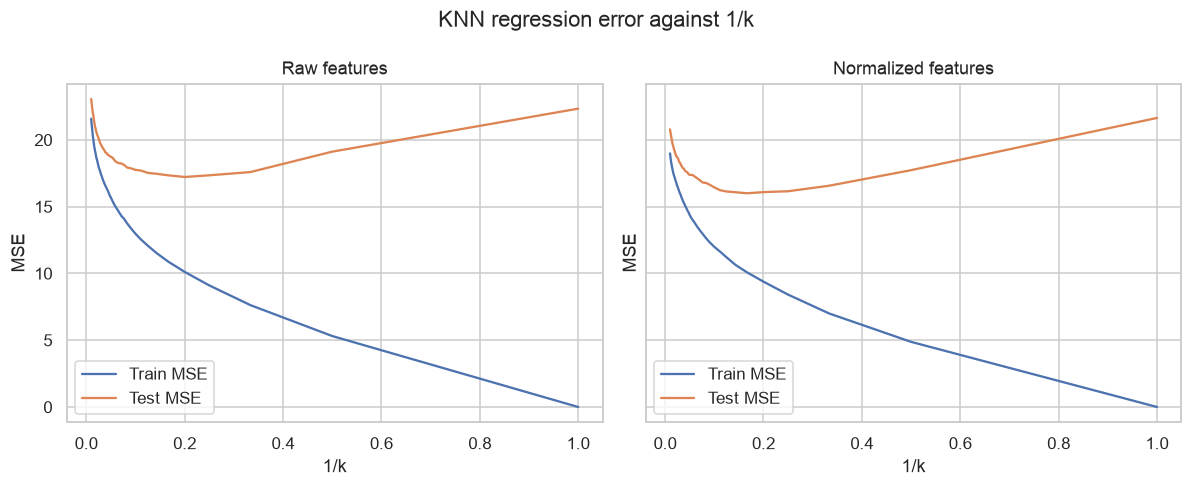

In [12]:
features = ["T", "V", "AP", "RH"]
x_train = train[features].to_numpy()
y_train = train["EP"].to_numpy()
x_test = test[features].to_numpy()
y_test = test["EP"].to_numpy()

scaler = StandardScaler().fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)


def knn_errors(train_features, test_features):
    train_mse = []
    test_mse = []
    for n_neighbors in range(1, 101):
        model = KNeighborsRegressor(n_neighbors=n_neighbors)
        model.fit(train_features, y_train)
        train_mse.append(mean_squared_error(y_train, model.predict(train_features)))
        test_mse.append(mean_squared_error(y_test, model.predict(test_features)))
    return np.asarray(train_mse), np.asarray(test_mse)


raw_train_mse, raw_test_mse = knn_errors(x_train, x_test)
scaled_train_mse, scaled_test_mse = knn_errors(x_train_scaled, x_test_scaled)
neighbors = np.arange(1, 101)

raw_best_k = int(neighbors[np.argmin(raw_test_mse)])
scaled_best_k = int(neighbors[np.argmin(scaled_test_mse)])
knn_summary = pd.DataFrame(
    {
        "best_k": [raw_best_k, scaled_best_k],
        "train_mse": [
            raw_train_mse[raw_best_k - 1],
            scaled_train_mse[scaled_best_k - 1],
        ],
        "test_mse": [
            raw_test_mse[raw_best_k - 1],
            scaled_test_mse[scaled_best_k - 1],
        ],
    },
    index=["raw", "normalized"],
)
display(knn_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for axis, train_mse, test_mse, title in (
    (axes[0], raw_train_mse, raw_test_mse, "Raw features"),
    (axes[1], scaled_train_mse, scaled_test_mse, "Normalized features"),
):
    axis.plot(1 / neighbors, train_mse, label="Train MSE")
    axis.plot(1 / neighbors, test_mse, label="Test MSE")
    axis.set_xlabel("1/k")
    axis.set_ylabel("MSE")
    axis.set_title(title)
    axis.legend()
fig.suptitle("KNN regression error against 1/k")
fig.tight_layout()
plt.show()


KNN uses the same 70/30 split as part (h). The scaler is fit on the training set only. The best `k` is the one with the smallest test MSE.

- Raw features: best `k` is 5, with test MSE about 17.22 (training MSE about 10.12).
- Normalized features: best `k` is 6, with test MSE about 16.00 (training MSE about 10.08).

Normalization is better. `AP` is orders of magnitude larger than `T`, so unscaled Euclidean distance is dominated by pressure. The training error at `k = 1` is 0 because each training point is its own nearest neighbor; the test curve is the one that selects `k`. Both test curves fall from `k = 1`, reach a minimum near `1/k` of about 0.2, and then rise again as `k` becomes large.


### (j) Compare KNN and Linear


In [13]:
comparison_mse = pd.DataFrame(
    {
        "model": [
            "Linear, all predictors",
            "Linear, selected interactions and quadratics",
            f"KNN raw, k={raw_best_k}",
            f"KNN normalized, k={scaled_best_k}",
        ],
        "test_mse": [
            baseline_test_mse,
            improved_test_mse,
            raw_test_mse[raw_best_k - 1],
            scaled_test_mse[scaled_best_k - 1],
        ],
    }
)
comparison_mse


,model,test_mse
0,"Linear, all predictors",21.7414
1,"Linear, selected interactions and quadratics",19.0829
2,"KNN raw, k=5",17.2225
3,"KNN normalized, k=6",16.0017


The better linear model is the reduced interaction-and-quadratic regression, with test MSE about 19.08. The better KNN model is normalized features with `k = 6`, with test MSE about 16.00. KNN has the smaller test error.

That matches parts (f) and (g): several predictors have quadratic or cubic signal, and several interactions are significant, so a local method can improve on a single linear equation. The linear model is still close, and unlike KNN it gives coefficients that can be read as effects of temperature, vacuum, pressure, and humidity. The multiple linear `R^2` of about 0.93 already says the leading pattern is nearly linear. KNN spends that remaining gap on local nonlinearity, at the cost of a less interpretable fit and a training error well below its test error.


## 2. ISLR: 2.4.1


For each setting, the comparison is between a flexible method and an inflexible method such as linear regression.


### (a) The sample size n is extremely large, and the number of predictors p is small.


In [14]:
print(
    "A flexible method should perform better. "
    "With many observations and few predictors, its extra variance stays small, "
    "while the lower bias lets it follow structure that an inflexible method misses."
)


A flexible method should perform better. With many observations and few predictors, its extra variance stays small, while the lower bias lets it follow structure that an inflexible method misses.


### (b) The number of predictors p is extremely large, and the number of observations n is small.


In [15]:
print(
    "A flexible method should perform worse. "
    "There are too few observations to estimate a flexible fit, so it overfits. "
    "An inflexible method has lower variance and is more stable."
)


A flexible method should perform worse. There are too few observations to estimate a flexible fit, so it overfits. An inflexible method has lower variance and is more stable.


### (c) The relationship between the predictors and response is highly non-linear.


In [16]:
print(
    "A flexible method should perform better. "
    "An inflexible linear fit has high bias when the regression function curves. "
    "Flexibility is needed to follow that curve."
)


A flexible method should perform better. An inflexible linear fit has high bias when the regression function curves. Flexibility is needed to follow that curve.


### (d) The variance of the error terms, i.e. $\sigma^2$ = Var($\epsilon$), is extremely high.


In [17]:
print(
    "A flexible method should perform worse. "
    "A large error variance means a flexible fit will track noise. "
    "An inflexible method smooths through that noise and has lower variance."
)


A flexible method should perform worse. A large error variance means a flexible fit will track noise. An inflexible method smooths through that noise and has lower variance.


## 3. ISLR: 2.4.7


The training set is the six observations in ISLR Exercise 2.4.7. The test point is `X1 = X2 = X3 = 0`.


### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.


In [18]:
observations = pd.DataFrame(
    {
        "X1": [0, 2, 0, 0, -1, 1],
        "X2": [3, 0, 1, 1, 0, 1],
        "X3": [0, 0, 3, 2, 1, 1],
        "Y": ["Red", "Red", "Red", "Green", "Green", "Red"],
    },
    index=np.arange(1, 7),
)
observations.index.name = "Obs"
test_point = np.zeros(3)
observations["distance"] = np.linalg.norm(
    observations[["X1", "X2", "X3"]].to_numpy() - test_point, axis=1
)
observations


,X1,X2,X3,Y,distance
Obs,,,,,
1,0,3,0,Red,3.0000
2,2,0,0,Red,2.0000
3,0,1,3,Red,3.1623
4,0,1,2,Green,2.2361
5,-1,0,1,Green,1.4142
6,1,1,1,Red,1.7321


### (b) What is our prediction with K = 1? Why?


In [19]:
nearest = observations.sort_values("distance")
print(nearest[["Y", "distance"]].head(3))
print("K = 1 prediction:", nearest.iloc[0]["Y"])


         Y  distance
Obs                 
5    Green    1.4142
6      Red    1.7321
2      Red    2.0000
K = 1 prediction: Green


`K = 1` predicts **Green**. Observation 5 is the unique nearest neighbor, at distance `sqrt(2)` (about 1.414), and its label is Green.


### (c) What is our prediction with K = 3? Why?


In [20]:
three_neighbors = nearest.head(3)
print(three_neighbors["Y"].value_counts())
print("K = 3 prediction:", three_neighbors["Y"].mode().iloc[0])


Y
Red      2
Green    1
Name: count, dtype: int64
K = 3 prediction: Red


`K = 3` predicts **Red**. The three nearest observations are 5 (Green, distance about 1.414), 6 (Red, distance about 1.732), and 2 (Red, distance 2). Two of the three labels are Red, so the majority vote is Red.


### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?


In [21]:
print(
    "The best K should be small. "
    "A small neighborhood can follow a wiggly Bayes boundary. "
    "A large K averages over a wide region and forces a smoother boundary."
)


The best K should be small. A small neighborhood can follow a wiggly Bayes boundary. A large K averages over a wide region and forces a smoother boundary.
